# AI-Based Wildfire Occurrence Risk Assessment
## Bayesian Model Averaging · Application project · Unit 5

**Research question:** Can environmental conditions predict whether a recorded fire has a strictly positive recorded burned area?

**Deliverable:** a reproducible comparative experiment plus a functional Streamlit probability interface. This notebook runs the same source code used by the app and regenerates measured tables, plots and saved models.

### Target definition comes first
UCI Forest Fires was created for burned-area regression, with 517 fire records from Montesinho Natural Park, Portugal. It does not supply representative non-fire observation days. We define `y = 1[area > 0]` **before examining model performance**. A zero recorded area must not be interpreted as a confirmed non-fire day. The estimand is a **positive recorded-area proxy conditional on a fire record**, not population ignition risk. Actual occurrence prediction requires event/non-event sampling with exposure windows.

**Attribution:** Cortez, P. & Morais, A. (2007). *Forest Fires*. UCI Machine Learning Repository. [DOI: 10.24432/C5D88D](https://doi.org/10.24432/C5D88D). Dataset license: CC BY 4.0. [Official data page](https://archive.ics.uci.edu/dataset/162/forest%2Bfires).

### Reproducibility
From the project folder: `python -m pip install -r requirements.txt -c requirements-lock.txt`, then open this notebook. Run all cells in order. Training is deterministic given the package environment; timing values vary by hardware. No report or presentation is generated.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/wildfire').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from wildfire.data import load_data, feature_frame, grouped_split, RAW_FEATURES, FEATURES
from wildfire.train import run_experiment
df = load_data()
y = (df['area'] > 0).astype(int)
print('Project:', ROOT)
print('Rows / columns:', df.shape)
display(df.head())

Project: C:\Users\Rian K Sinu\Documents\Codex\2026-11-05\3-ai-based-wildfire-occurrence-risk\outputs\wildfire-risk
Rows / columns: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


## 1. Audit the source data
Keep the original records and original CSV. Exact duplicates are described rather than removed: all identical `(X,Y)` locations are assigned together, so identical records cannot cross splits. Rows may still share weather events across cells, an unresolved dependence limitation. Missing/invalid values fail validation rather than being silently filled from the full dataset.

In [2]:
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique()})
display(audit)
print('Exact duplicate rows:', df.duplicated().sum())
display(pd.DataFrame({'target': ['area = 0', 'area > 0'], 'count': [(y == 0).sum(), (y == 1).sum()]}))
display(df[RAW_FEATURES[:-1] + ['area']].describe().T)
assert df.shape == (517, 13)
assert set(y.unique()) == {0, 1}

,dtype,missing,unique
X,int64,0,9
Y,int64,0,7
month,str,0,12
day,str,0,7
FFMC,float64,0,106
DMC,float64,0,215
DC,float64,0,219
ISI,float64,0,119
temp,float64,0,192
RH,int64,0,75


Exact duplicate rows: 4


,target,count
0,area = 0,247
1,area > 0,270


,count,mean,std,min,25%,50%,75%,max
temp,517.0,18.889168,5.806625,2.2,15.5,19.30,22.80,33.30
RH,517.0,44.288201,16.317469,15.0,33.0,42.00,53.00,100.00
wind,517.0,4.017602,1.791653,0.4,2.7,4.00,4.90,9.40
rain,517.0,0.021663,0.295959,0.0,0.0,0.00,0.00,6.40
FFMC,517.0,90.644681,5.520111,18.7,90.2,91.60,92.90,96.20
DMC,517.0,110.872340,64.046482,1.1,68.6,108.30,142.40,291.30
DC,517.0,547.940039,248.066192,7.9,437.7,664.20,713.90,860.60
ISI,517.0,9.021663,4.559477,0.0,6.5,8.40,10.80,56.10
area,517.0,12.847292,63.655818,0.0,0.0,0.52,6.57,1090.84


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(df.temp, bins=20, color='#377c75'); axes[0].set(xlabel='Temperature (°C)', ylabel='Records')
axes[1].hist(df.RH, bins=20, color='#377c75'); axes[1].set(xlabel='Relative humidity (%)')
axes[2].hist(np.log1p(df.area), bins=20, color='#c85b32'); axes[2].set(xlabel='log(1 + recorded area)')
fig.suptitle('Descriptive full-data audit; no modeling choices selected from test outcomes')
plt.tight_layout(); plt.show()

C:\Users\Rian K Sinu\AppData\Local\Temp\ipykernel_31292\1342184931.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 2. Prespecified spatial holdouts
Use `(X,Y)` as the repeated-location group. `GroupShuffleSplit(seed=42)` holds out 20% of cells for test; seed 43 holds out 25% of remaining cells for validation. These are group proportions, not row proportions. Do not try many seeds and keep the best result.

Month/day names do not provide full timestamps or years. Sorting alphabetic month/day names would invent a chronology, so this project makes no temporal generalization claim. X/Y are excluded from model inputs, because this experiment measures transfer to unseen grid cells.

Four-fold grouped CV uses **training only** for hyperparameter selection. Validation later selects classification thresholds. Test outcomes never determine preprocessing, hyperparameters, thresholds, model evidence or model weights.

In [4]:
splits, groups = grouped_split(df)
summary = pd.DataFrame([{'split': name, 'records': len(ids), 'groups': groups.iloc[ids].nunique(),
                         'positive_fraction': y.iloc[ids].mean()} for name, ids in splits.items()])
display(summary)
group_sets = [set(groups.iloc[ids]) for ids in splits.values()]
assert all(group_sets[i].isdisjoint(group_sets[j]) for i in range(3) for j in range(i+1, 3))
assert len(set(np.concatenate(list(splits.values())))) == len(df)

,split,records,groups,positive_fraction
0,train,237,21,0.464135
1,validation,89,7,0.539326
2,test,191,8,0.586387


## 3. Environmental preprocessing
Inputs: temperature (°C), RH (%), wind (km/h), rain (UCI `mm/m²` units), FFMC, DMC, DC, ISI and month. Rain is transformed by `log1p` and month has deterministic cyclic sine/cosine encoding. These transformations do not learn from data. Standardization learns mean/scale **inside each training fold** through a scikit-learn Pipeline, and is refit on training only for the selected model. Trees receive the same feature matrix for comparison.

Burned area enters only the label. X/Y enter only grouping; day of week is excluded. FWI components are provided measurements; the application does not claim to compute them from one day's weather.

In [5]:
X = feature_frame(df)
display(X.head())
assert list(X.columns) == FEATURES
assert not {'area', 'X', 'Y', 'day'} & set(X.columns)
assert np.isfinite(X.to_numpy()).all()

,temp,RH,wind,log_rain,DMC,DC,FFMC,ISI,month_sin,month_cos
0,8.2,51,6.7,0.000000,26.2,94.3,86.2,5.1,0.866025,5.000000e-01
1,18.0,33,0.9,0.000000,35.4,669.1,90.6,6.7,-1.000000,-1.836970e-16
2,14.6,33,1.3,0.000000,43.7,686.9,90.6,6.7,-1.000000,-1.836970e-16
3,8.3,97,4.0,0.182322,33.3,77.5,91.7,9.0,0.866025,5.000000e-01
4,11.4,99,1.8,0.000000,51.3,102.2,89.3,9.6,0.866025,5.000000e-01


## 4. Bayesian Model Averaging
The candidate family contains every subset of four prespecified feature blocks, for $2^4=16$ logistic models, including an intercept-only model:

| Block | Inputs |
|---|---|
| weather | temperature, RH, wind, log(1 + rain) |
| moisture | DMC, DC |
| fire_indices | FFMC, ISI |
| season | month sine, month cosine |

For model $M_m$, $y_i\sim\mathrm{Bernoulli}(\sigma(x_{im}^T\beta_m))$ and $\beta_m\sim N(0,s^2I)$, including the intercept. Inputs are standardized. All models have prior probability $1/16$. The prior scale $s\in\{1,2.5\}$ is selected using training-only grouped CV Brier score. This is empirical selection of a prior scale, not full Bayesian integration over hyperparameters.

At the maximum a posteriori estimate $\hat\beta_m$, let $H_m$ be the Hessian of the negative log posterior. Laplace evidence is
$$\log Z_m\approx\ell_m(\hat\beta_m)+\log p(\hat\beta_m\mid M_m)+\frac{k_m}{2}\log(2\pi)-\frac12\log|H_m|.$$
The normalized Gaussian prior is retained. Weights are computed stably as
$$w_m=\mathrm{softmax}_m(\log Z_m+\log p(M_m)).$$
The average is $p(y_*=1\mid x_*,D)\approx\sum_m w_m E_{N(\hat\beta_m,H_m^{-1})}[\sigma(x_{*m}^T\beta_m)]$; 20-point Gauss-Hermite quadrature integrates the Gaussian linear predictor.

This is **approximate Bayesian model averaging**, not averaging classifier accuracies, stacking, or an exact evidence calculation. Evidence weights are conditional on the candidate family, preprocessing and selected prior. They are not causal feature effects or guarantees of predictive skill.

## 5. Fit candidates, tune alternatives and freeze decisions
Compare BMA with Logistic Regression (`C`: .01, .1, 1, 10), Decision Tree (depth 2/4/6, leaf size 5/15), Random Forest (200 trees; depth 3/unrestricted, leaf size 5/15), and a training-prevalence baseline. All use the exact same grouped inner folds and the same held-out rows.

Select hyperparameters by mean inner-CV Brier (lower is better). Fit selected configurations on training only. Each model selects its F1 threshold on validation over .05 to .95 in .01 steps; ties favor the threshold closest to .5. Validation F1 is therefore optimistic. Validation Brier is not the hyperparameter selection score. Report test F1 at both the frozen threshold and .5.

No post-hoc calibration transformation is fitted: the required calibration check assesses the original probabilities. The test set is for this final comparison, not repeated model redesign.

In [6]:
comparison = run_experiment()
display(comparison)
metadata = json.loads((ROOT / 'artifacts/metadata.json').read_text())
display(metadata['best_parameters'])

Fitting BMA...


Fitting Logistic Regression...


Fitting Decision Tree...


Fitting Random Forest...


Fitting Prevalence Baseline...


          algorithm  validation_brier  test_roc_auc  test_f1  test_brier
                BMA          0.253805      0.526334 0.739274    0.257385
Logistic Regression          0.249327      0.493332 0.716312    0.259588
      Decision Tree          0.251387      0.542326 0.549020    0.261372
      Random Forest          0.237463      0.541478 0.715789    0.257630
Prevalence Baseline          0.254107      0.500000 0.739274    0.257483


,algorithm,cv_brier,threshold,training_seconds_including_search,selected_fit_seconds,inference_ms_per_row_batch,interpretability,validation_roc_auc,validation_f1,validation_brier,validation_log_loss,validation_f1_at_0_5,test_roc_auc,test_f1,test_brier,test_log_loss,test_f1_at_0_5
0,BMA,0.252455,0.46,0.227401,0.016039,0.016470,Weighted logistic subsets; block inclusion pro...,0.560467,0.700730,0.253805,0.700771,0.000000,0.526334,0.739274,0.257385,0.707944,0.000000
1,Logistic Regression,0.256518,0.41,0.202676,0.004931,0.011547,Standardized coefficients,0.569106,0.744186,0.249327,0.691593,0.169492,0.493332,0.716312,0.259588,0.712454,0.147059
2,Decision Tree,0.275169,0.42,0.184709,0.005364,0.010220,Decision rules (depth-limited),0.652185,0.714286,0.251387,0.703238,0.473684,0.542326,0.549020,0.261372,0.715558,0.417178
3,Random Forest,0.262163,0.36,6.512350,0.372203,0.099971,Ensemble; global feature importance,0.660061,0.738462,0.237463,0.666982,0.595238,0.541478,0.715789,0.257630,0.709382,0.491803
4,Prevalence Baseline,0.251676,0.46,0.047679,0.004167,0.007208,Training positive-class frequency,0.500000,0.700730,0.254107,0.701378,0.000000,0.500000,0.739274,0.257483,0.708141,0.000000


{'BMA': {'model__prior_scale': 2.5},
 'Logistic Regression': {'model__C': 0.01},
 'Decision Tree': {'model__max_depth': 2, 'model__min_samples_leaf': 5},
 'Random Forest': {'model__max_depth': 3, 'model__min_samples_leaf': 15},
 'Prevalence Baseline': {}}

## 6. Shared-test comparison
ROC-AUC assesses ranking. F1 depends on threshold and prevalence. Brier is mean squared probability error; it combines calibration and discrimination, so a low Brier score alone does not establish perfect calibration. Log loss is also provided.

Training time includes CV search plus the selected refit; refit time is shown separately. Inference time is the mean of 30 warmed test-batch predictions divided by row count, including pipeline transformations but excluding loading/I/O. It is not single-request latency. No model is assumed to outperform the baseline.

,algorithm,cv_brier,validation_brier,test_roc_auc,test_f1,test_f1_at_0_5,test_brier,threshold,training_seconds_including_search,selected_fit_seconds,inference_ms_per_row_batch,interpretability
0,BMA,0.2525,0.2538,0.5263,0.7393,0.0000,0.2574,0.46,0.2274,0.0160,0.0165,Weighted logistic subsets; block inclusion pro...
1,Logistic Regression,0.2565,0.2493,0.4933,0.7163,0.1471,0.2596,0.41,0.2027,0.0049,0.0115,Standardized coefficients
2,Decision Tree,0.2752,0.2514,0.5423,0.5490,0.4172,0.2614,0.42,0.1847,0.0054,0.0102,Decision rules (depth-limited)
3,Random Forest,0.2622,0.2375,0.5415,0.7158,0.4918,0.2576,0.36,6.5123,0.3722,0.1000,Ensemble; global feature importance
4,Prevalence Baseline,0.2517,0.2541,0.5000,0.7393,0.0000,0.2575,0.46,0.0477,0.0042,0.0072,Training positive-class frequency


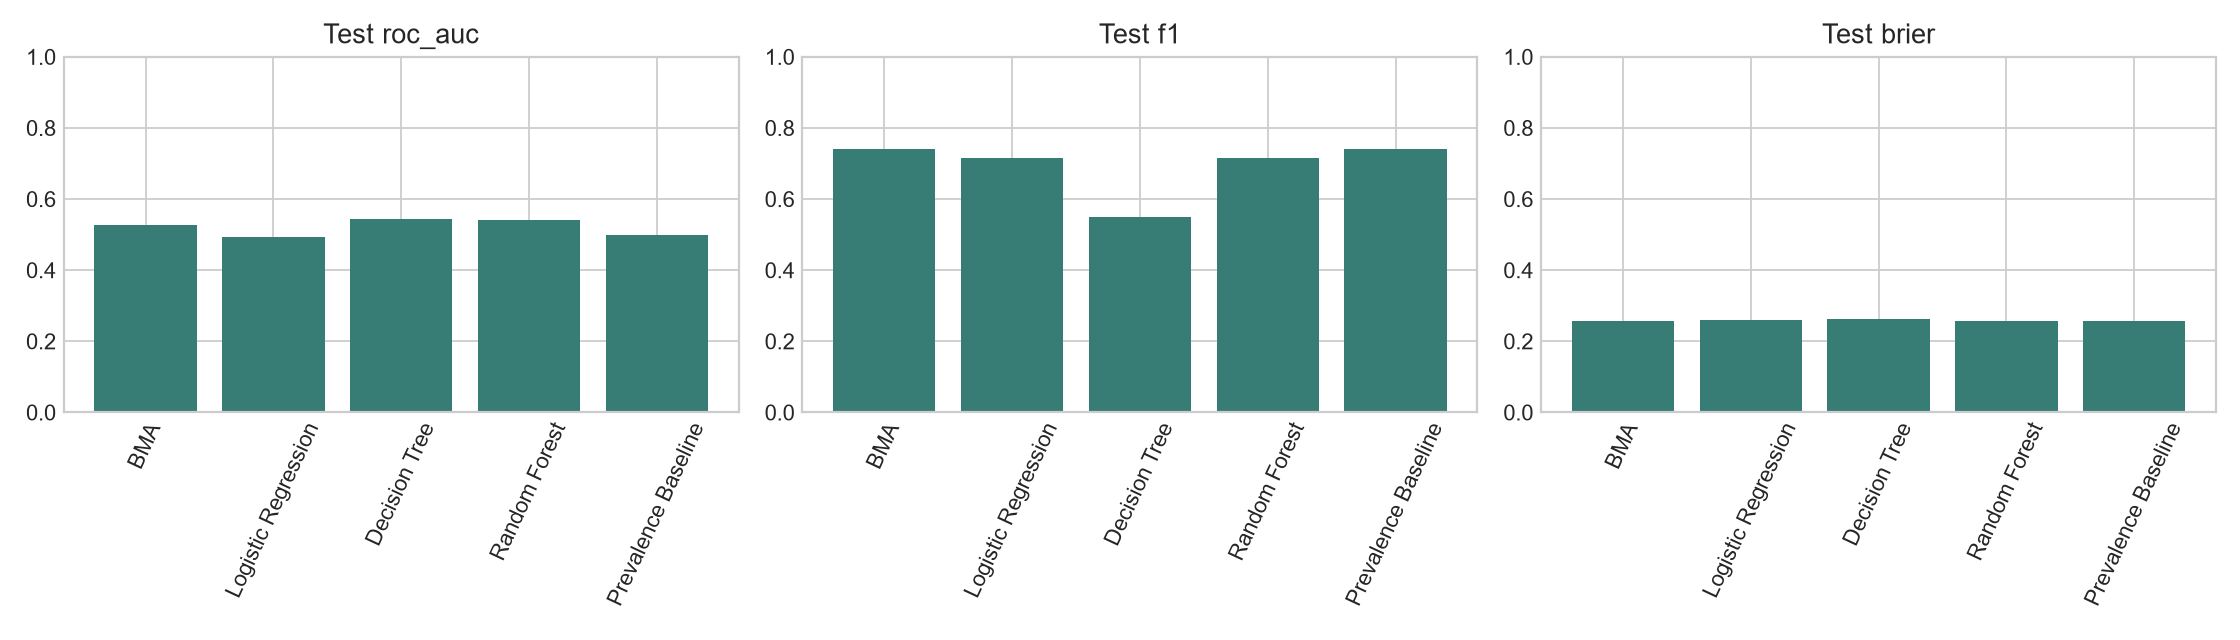

In [7]:
columns = ['algorithm', 'cv_brier', 'validation_brier', 'test_roc_auc', 'test_f1', 'test_f1_at_0_5',
           'test_brier', 'threshold', 'training_seconds_including_search',
           'selected_fit_seconds', 'inference_ms_per_row_batch', 'interpretability']
display(comparison[columns].round(4))
display(Image(filename=str(ROOT / 'artifacts/comparison.png')))

## 7. Model weights and block inclusion
Candidate weights sum to one. Block inclusion is the sum of posterior model weights for models containing that block. Inspect whether the intercept-only model has material support: complex weather relationships may not be supported by these data.

,candidate,weight,log_evidence,parameters,gradient_max
0,intercept_only,9.734897e-01,-166.623265,1,1.255380e-07
1,moisture,1.181207e-02,-171.035030,3,5.246148e-10
2,season,1.030695e-02,-171.171334,3,8.557484e-10
3,fire_indices,4.054514e-03,-172.104321,3,1.122823e-10
4,moisture + season,1.598775e-04,-175.337499,5,7.749504e-10
5,weather,7.371521e-05,-176.111698,5,5.153226e-10
6,moisture + fire_indices,5.234988e-05,-176.453957,5,6.516606e-10
7,fire_indices + season,4.775970e-05,-176.545725,5,1.107715e-09
8,weather + season,1.113867e-06,-180.304069,7,1.212051e-08
9,moisture + fire_indices + season,7.594649e-07,-180.687048,7,1.028183e-09


,block,inclusion_probability
0,weather,0.000076
1,moisture,0.012026
2,fire_indices,0.004156
3,season,0.010516


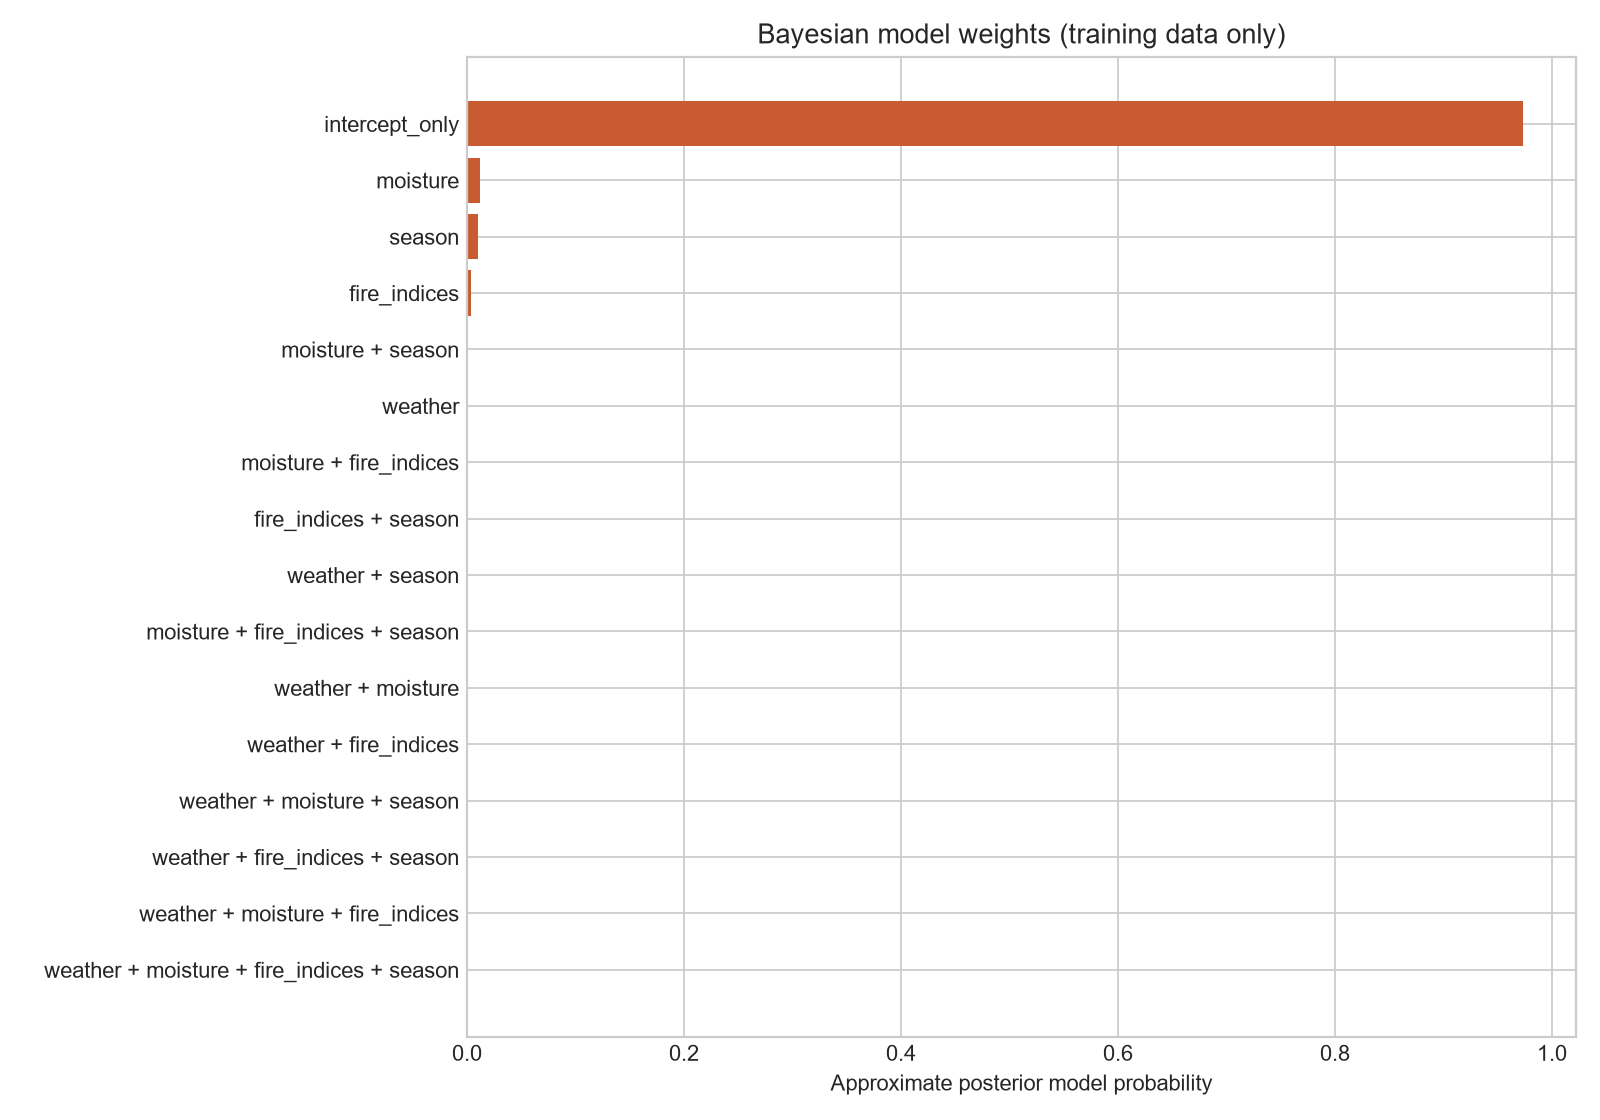

In [8]:
weights = pd.read_csv(ROOT / 'artifacts/bma_weights.csv')
assert np.isclose(weights.weight.sum(), 1)
assert (weights.gradient_max < 1e-4).all()
display(weights)
display(pd.read_csv(ROOT / 'artifacts/block_inclusion.csv'))
display(Image(filename=str(ROOT / 'artifacts/model_weights.png')))

## 8. Calibration and errors
Plot reliability in five fixed equal-width probability bins against the ideal diagonal. Persist counts and observed proportions for every occupied bin. Empty bins are omitted, not treated as zero. Small samples create noisy curves; this is a diagnostic, not evidence that all probabilities are reliable. ROC and calibration use the same held-out spatial rows for every model. No test-fitted calibrator feeds predictions back into evaluation.

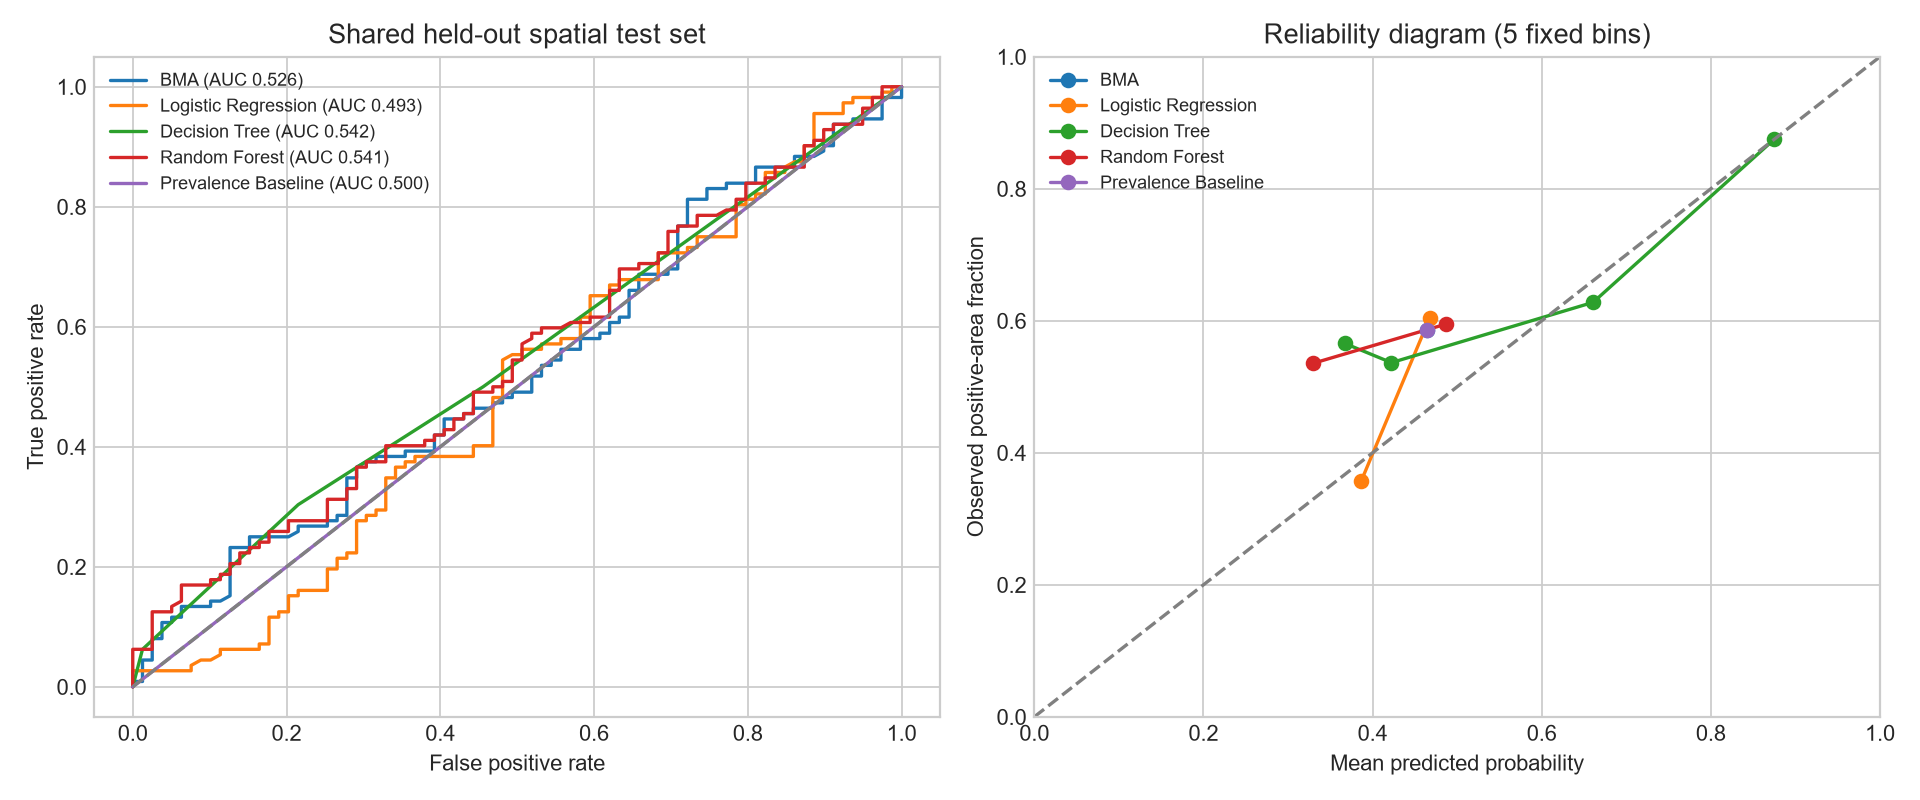

,algorithm,bin,count,mean_probability,observed_fraction
0,BMA,2,191,0.464282,0.586387
1,Logistic Regression,1,14,0.386504,0.357143
2,Logistic Regression,2,177,0.467597,0.604520
3,Decision Tree,1,99,0.367188,0.565657
4,Decision Tree,2,41,0.422222,0.536585
5,Decision Tree,3,43,0.660714,0.627907
6,Decision Tree,4,8,0.875000,0.875000
7,Random Forest,1,28,0.330007,0.535714
8,Random Forest,2,163,0.487057,0.595092
9,Prevalence Baseline,2,191,0.464135,0.586387


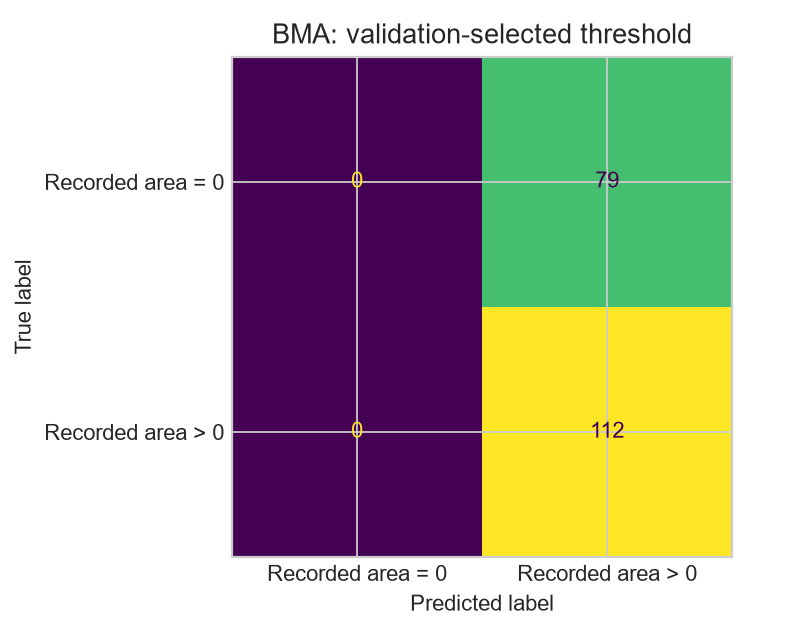

BMA: test Brier 0.2574; improvement over baseline +0.0001
Logistic Regression: test Brier 0.2596; improvement over baseline -0.0021
Decision Tree: test Brier 0.2614; improvement over baseline -0.0039
Random Forest: test Brier 0.2576; improvement over baseline -0.0001
Prevalence Baseline: test Brier 0.2575; improvement over baseline +0.0000


In [9]:
display(Image(filename=str(ROOT / 'artifacts/roc_calibration.png')))
display(pd.read_csv(ROOT / 'artifacts/calibration_bins.csv'))
display(Image(filename=str(ROOT / 'artifacts/bma_confusion.png')))
baseline = comparison.set_index('algorithm').loc['Prevalence Baseline', 'test_brier']
for _, row in comparison.iterrows():
    print(f"{row.algorithm}: test Brier {row.test_brier:.4f}; improvement over baseline {baseline - row.test_brier:+.4f}")

## 9. Load the application model and score a scenario
The app uses the same serialized pipelines, selected thresholds and data schema. Inputs are validated and extrapolation beyond training ranges is flagged. Uploaded batch CSVs are scored locally; downloadable results include each model's probability. Between-model disagreement is explicitly distinguished from a confidence interval.

In [10]:
import joblib
bundle = joblib.load(ROOT / 'artifacts/models.joblib')  # trusted, locally generated artifact only
scenario = pd.DataFrame([dict(temp=20.0, RH=45.0, wind=4.0, rain=0.0,
                              FFMC=90.0, DMC=110.0, DC=550.0, ISI=8.0, month='aug')])
scenario_X = feature_frame(scenario)
display(pd.DataFrame([{'algorithm': name, 'positive_recorded_area_probability': model.predict_proba(scenario_X)[0, 1],
                       'threshold': bundle['thresholds'][name]} for name, model in bundle['models'].items()]))
print('Launch from project folder: python -m streamlit run app.py')

,algorithm,positive_recorded_area_probability,threshold
0,BMA,0.464463,0.46
1,Logistic Regression,0.468897,0.41
2,Decision Tree,0.660714,0.42
3,Random Forest,0.512342,0.36
4,Prevalence Baseline,0.464135,0.46


Launch from project folder: python -m streamlit run app.py


## 10. Interpretation, limitations and next steps
* This dataset supports positive recorded-area classification among fire records; it cannot validate daily ignition risk. Obtain representative fire and non-fire exposure records before making an occurrence claim.
* Only one small park dataset is available. Grouped spatial holdout reduces location leakage, but shared weather/event dependence across cells may remain. There are no full timestamps for chronological validation.
* All estimates are conditional on one prespecified split. Small test size and sparse probability bins limit precision. No confidence intervals or external validation are claimed.
* BMA uses a restricted logistic candidate family and Laplace approximations; a second prior scale is assessed within training CV. A wider family or exact posterior inference could change the weights.
* F1 thresholds optimize a statistical criterion on a small validation set, not firefighting costs or policy. The interface is an educational research demonstration.
* If ranking or Brier is weak relative to baseline, report it as measured. Do not change the held-out set or manufacture higher accuracy.

### Files produced
`artifacts/` contains the common split assignments, CV search results, comparison table, test probabilities, calibration-bin counts, model weights, block inclusion, plots, model bundle and environment/data-hash metadata. `app.py` provides the working interface; `tests/` checks spatial separation, leakage, BMA normalization, inference stability and application prediction.

### References
* [UCI Forest Fires](https://archive.ics.uci.edu/dataset/162/forest%2Bfires)
* [scikit-learn probability calibration documentation](https://scikit-learn.org/stable/modules/calibration.html)
* [SciPy minimize documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
